In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [7]:
df = pd.read_csv('heart_disease.csv')

df.head()


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [9]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   10000 non-null  float64
 1   Gender                10000 non-null  int64  
 2   Blood Pressure        10000 non-null  float64
 3   Cholesterol Level     10000 non-null  float64
 4   Exercise Habits       10000 non-null  int64  
 5   Smoking               10000 non-null  int64  
 6   Family Heart Disease  10000 non-null  int64  
 7   Diabetes              10000 non-null  int64  
 8   BMI                   10000 non-null  float64
 9   High Blood Pressure   10000 non-null  int64  
 10  Low HDL Cholesterol   10000 non-null  int64  
 11  High LDL Cholesterol  10000 non-null  int64  
 12  Alcohol Consumption   10000 non-null  int64  
 13  Stress Level          10000 non-null  int64  
 14  Sleep Hours           10000 non-null  float64
 15  Sugar Consumption     10000 non

In [ ]:
df.describe()

df = df.fillna(df.median(numeric_only=True))

print(df.isnull().sum())


Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Exercise Habits         0
Smoking                 0
Family Heart Disease    0
Diabetes                0
BMI                     0
High Blood Pressure     0
Low HDL Cholesterol     0
High LDL Cholesterol    0
Alcohol Consumption     0
Stress Level            0
Sleep Hours             0
Sugar Consumption       0
Triglyceride Level      0
Fasting Blood Sugar     0
CRP Level               0
Homocysteine Level      0
Heart Disease Status    0
dtype: int64


In [11]:

for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col])

In [3]:
x = df.drop(['Heart Disease Status'], axis=1)
y = df['Heart Disease Status']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
model = LogisticRegression(max_iter=5000, class_weight='balanced')
model.fit(x_train, y_train)

model_predict = model.predict(x_test)

Confusion Matrix:
[[841 759]
 [223 177]]


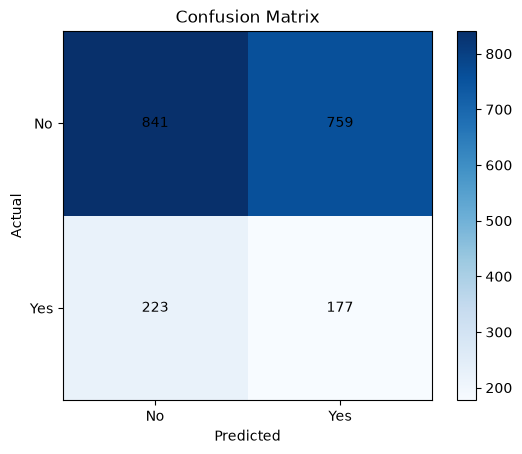

In [15]:
cm = confusion_matrix(y_test, model_predict)

print("Confusion Matrix:")
print(cm)


plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [6]:
precision = precision_score(y_test, model_predict)
print("Precision:", precision)

recall = recall_score(y_test, model_predict)
print("Recall:", recall)

f1 = f1_score(y_test, model_predict)
print("F1 Score:", f1)

Precision: 0.1891025641025641
Recall: 0.4425
F1 Score: 0.26497005988023953
